In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import SimpleExpSmoothing

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

In [2]:
# pip install statsmodels

In [3]:
sales = [100, 120, 110, 130, 150,
         170, 160, 180, 200, 190]

months = ["Jan", "Feb", "Mar", "Apr", "May",
          "Jun", "Jul", "Aug", "Sep", "Oct"]

In [4]:
df=pd.DataFrame({"Month":months,"Sales":sales})
print("Orginal Data")
print(df)

Orginal Data
  Month  Sales
0   Jan    100
1   Feb    120
2   Mar    110
3   Apr    130
4   May    150
5   Jun    170
6   Jul    160
7   Aug    180
8   Sep    200
9   Oct    190


In [5]:
alpha = 0.3

In [11]:
model = SimpleExpSmoothing(df['Sales'],initialization_method="estimated")

In [12]:
model_fit = model.fit(
    smoothing_level=alpha,
    optimized=False
)

In [14]:
df["SES_Forecast"] = model_fit.fittedvalues

next_forecast = model_fit.forecast(1)

print("\nForecast for Next Month")

print(next_forecast)

print("\nForecasted Data")

print(df)


Forecast for Next Month
10    174.866467
dtype: float64

Forecasted Data
  Month  Sales  SES_Forecast
0   Jan    100     90.000000
1   Feb    120     93.000000
2   Mar    110    101.100000
3   Apr    130    103.770000
4   May    150    111.639000
5   Jun    170    123.147300
6   Jul    160    137.203110
7   Aug    180    144.042177
8   Sep    200    154.829524
9   Oct    190    168.380667



Forecasted Data
  Month  Sales  SES_Forecast
0   Jan    100     90.000000
1   Feb    120     93.000000
2   Mar    110    101.100000
3   Apr    130    103.770000
4   May    150    111.639000
5   Jun    170    123.147300
6   Jul    160    137.203110
7   Aug    180    144.042177
8   Sep    200    154.829524
9   Oct    190    168.380667


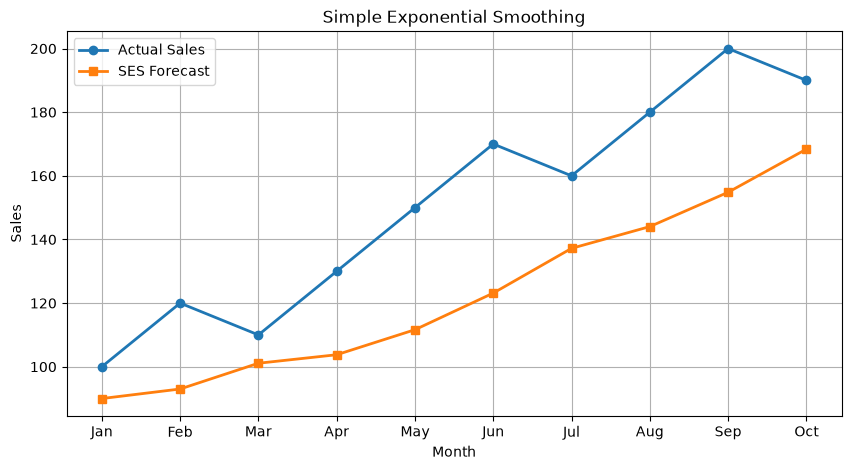


Evaluation Metrics
------------------------------
MAE  : 28.288822237000023
MSE  : 958.3395429001441
RMSE : 30.95705966173377
MAPE : 18.21 %


In [15]:
print("\nForecasted Data")

print(df)

plt.figure(figsize=(10,5))

plt.plot(
    df["Month"],
    df["Sales"],
    marker="o",
    linewidth=2,
    label="Actual Sales"
)

plt.plot(
    df["Month"],
    df["SES_Forecast"],
    marker="s",
    linewidth=2,
    label="SES Forecast"
)

plt.title("Simple Exponential Smoothing")

plt.xlabel("Month")

plt.ylabel("Sales")

plt.grid(True)

plt.legend()

plt.show()



mae = mean_absolute_error(
    df["Sales"],
    df["SES_Forecast"]
)

mse = mean_squared_error(
    df["Sales"],
    df["SES_Forecast"]
)

rmse = np.sqrt(mse)

mape = mean_absolute_percentage_error(
    df["Sales"],
    df["SES_Forecast"]
)

print("\nEvaluation Metrics")

print("------------------------------")

print("MAE  :", mae)

print("MSE  :", mse)

print("RMSE :", rmse)

print("MAPE :", round(mape*100,2), "%")